<a href="https://colab.research.google.com/github/Heptazero/ml-course-labs/blob/main/deep-learning/ch02_preliminaries.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 第2章 预备知识

## 2.1 数据操作

### 2.1.1 入门

In [1]:
import torch

x = torch.arange(12)
print(x)
print(x.shape)
print(x.numel())

X = x.reshape(3, 4)
print(X)

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
torch.Size([12])
12
tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])


In [2]:
print(torch.zeros((2, 3, 4)))
print(torch.ones((2, 3, 4)))
print(torch.randn(3, 4))
print(torch.tensor([[2, 1, 4, 3], [1, 2, 3, 4], [4, 3, 2, 1]]))

tensor([[[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]],

        [[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]]])
tensor([[[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]],

        [[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]]])
tensor([[ 0.7932,  0.6497,  0.5569,  0.3094],
        [ 1.2634,  0.9541,  0.6863,  0.7772],
        [ 0.1350, -0.7912,  1.2131, -0.1063]])
tensor([[2, 1, 4, 3],
        [1, 2, 3, 4],
        [4, 3, 2, 1]])


### 2.1.2 运算符

In [3]:
x = torch.tensor([1.0, 2, 4, 8])
y = torch.tensor([2, 2, 2, 2])
print(x + y, x - y, x * y, x / y, x ** y)  # **运算符是求幂运算
print(torch.exp(x))

tensor([ 3.,  4.,  6., 10.]) tensor([-1.,  0.,  2.,  6.]) tensor([ 2.,  4.,  8., 16.]) tensor([0.5000, 1.0000, 2.0000, 4.0000]) tensor([ 1.,  4., 16., 64.])
tensor([2.7183e+00, 7.3891e+00, 5.4598e+01, 2.9810e+03])


In [4]:
X = torch.arange(12, dtype=torch.float32).reshape((3, 4))
Y = torch.tensor([[2.0, 1, 4, 3], [1, 2, 3, 4], [4, 3, 2, 1]])
print(torch.cat((X, Y), dim=0))
print(torch.cat((X, Y), dim=1))
print(X == Y)
print(X.sum())

tensor([[ 0.,  1.,  2.,  3.],
        [ 4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11.],
        [ 2.,  1.,  4.,  3.],
        [ 1.,  2.,  3.,  4.],
        [ 4.,  3.,  2.,  1.]])
tensor([[ 0.,  1.,  2.,  3.,  2.,  1.,  4.,  3.],
        [ 4.,  5.,  6.,  7.,  1.,  2.,  3.,  4.],
        [ 8.,  9., 10., 11.,  4.,  3.,  2.,  1.]])
tensor([[False,  True, False,  True],
        [False, False, False, False],
        [False, False, False, False]])
tensor(66.)


### 2.1.3 广播机制

In [5]:
a = torch.arange(3).reshape((3, 1))
b = torch.arange(2).reshape((1, 2))
print(a, b)
print(a + b)

tensor([[0],
        [1],
        [2]]) tensor([[0, 1]])
tensor([[0, 1],
        [1, 2],
        [2, 3]])


### 2.1.4 索引和切片

In [6]:
print(X[-1], X[1:3])
X[1, 2] = 9
print(X)
X[0:2, :] = 12
print(X)

tensor([ 8.,  9., 10., 11.]) tensor([[ 4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11.]])
tensor([[ 0.,  1.,  2.,  3.],
        [ 4.,  5.,  9.,  7.],
        [ 8.,  9., 10., 11.]])
tensor([[12., 12., 12., 12.],
        [12., 12., 12., 12.],
        [ 8.,  9., 10., 11.]])


### 2.1.5 节省内存

In [7]:
before = id(Y)
Y = Y + X
print(id(Y) == before)

Z = torch.zeros_like(Y)
print('id(Z):', id(Z))
Z[:] = X + Y
print('id(Z):', id(Z))

before = id(X)
X += Y
print(id(X) == before)

False
id(Z): 132421548630944
id(Z): 132421548630944
True


### 2.1.6 转换为其他Python对象

In [8]:
A = X.numpy()
B = torch.tensor(A)
print(type(A), type(B))

a = torch.tensor([3.5])
print(a, a.item(), float(a), int(a))

<class 'numpy.ndarray'> <class 'torch.Tensor'>
tensor([3.5000]) 3.5 3.5 3


## 2.2 数据预处理

### 2.2.1 读取数据集

In [9]:
import os
import pandas as pd

os.makedirs(os.path.join('..', 'data'), exist_ok=True)
data_file = os.path.join('..', 'data', 'house_tiny.csv')
with open(data_file, 'w') as f:
    f.write('NumRooms,Alley,Price\n')  # 列名
    f.write('NA,Pave,127500\n')  # 每行表示一个数据样本
    f.write('2,NA,106000\n')
    f.write('4,NA,178100\n')
    f.write('NA,NA,140000\n')

data = pd.read_csv(data_file)
print(data)

   NumRooms Alley   Price
0       NaN  Pave  127500
1       2.0   NaN  106000
2       4.0   NaN  178100
3       NaN   NaN  140000


### 2.2.2 处理缺失值

In [10]:
inputs, outputs = data.iloc[:, 0:2], data.iloc[:, 2]
inputs = inputs.fillna(inputs.mean(numeric_only=True))
print(inputs)

inputs = pd.get_dummies(inputs, dummy_na=True)
print(inputs)

   NumRooms Alley
0       3.0  Pave
1       2.0   NaN
2       4.0   NaN
3       3.0   NaN
   NumRooms  Alley_Pave  Alley_nan
0       3.0        True      False
1       2.0       False       True
2       4.0       False       True
3       3.0       False       True


### 2.2.3 转换为张量格式

In [11]:
import torch

X = torch.tensor(inputs.to_numpy(dtype=float))
y = torch.tensor(outputs.to_numpy(dtype=float))
print(X)
print(y)

tensor([[3., 1., 0.],
        [2., 0., 1.],
        [4., 0., 1.],
        [3., 0., 1.]], dtype=torch.float64)
tensor([127500., 106000., 178100., 140000.], dtype=torch.float64)


## 2.3 线性代数

### 2.3.1 标量

In [12]:
import torch

x = torch.tensor(3.0)
y = torch.tensor(2.0)
print(x + y, x * y, x / y, x**y)

tensor(5.) tensor(6.) tensor(1.5000) tensor(9.)


### 2.3.2 向量

In [13]:
x = torch.arange(4)
print(x)
print(x[3])
print(len(x))
print(x.shape)

tensor([0, 1, 2, 3])
tensor(3)
4
torch.Size([4])


### 2.3.3 矩阵

In [14]:
A = torch.arange(20).reshape(5, 4)
print(A)
print(A.T)

B = torch.tensor([[1, 2, 3], [2, 0, 4], [3, 4, 5]])
print(B)
print(B == B.T)

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11],
        [12, 13, 14, 15],
        [16, 17, 18, 19]])
tensor([[ 0,  4,  8, 12, 16],
        [ 1,  5,  9, 13, 17],
        [ 2,  6, 10, 14, 18],
        [ 3,  7, 11, 15, 19]])
tensor([[1, 2, 3],
        [2, 0, 4],
        [3, 4, 5]])
tensor([[True, True, True],
        [True, True, True],
        [True, True, True]])


### 2.3.4 张量

In [15]:
X = torch.arange(24).reshape(2, 3, 4)
print(X)

tensor([[[ 0,  1,  2,  3],
         [ 4,  5,  6,  7],
         [ 8,  9, 10, 11]],

        [[12, 13, 14, 15],
         [16, 17, 18, 19],
         [20, 21, 22, 23]]])


### 2.3.5 张量算法的基本性质

In [16]:
A = torch.arange(20, dtype=torch.float32).reshape(5, 4)
B = A.clone()  # 通过分配新内存，将A的一个副本分配给B
print(A)
print(A + B)
print(A * B)

a = 2
X = torch.arange(24).reshape(2, 3, 4)
print(a + X)
print((a * X).shape)

tensor([[ 0.,  1.,  2.,  3.],
        [ 4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11.],
        [12., 13., 14., 15.],
        [16., 17., 18., 19.]])
tensor([[ 0.,  2.,  4.,  6.],
        [ 8., 10., 12., 14.],
        [16., 18., 20., 22.],
        [24., 26., 28., 30.],
        [32., 34., 36., 38.]])
tensor([[  0.,   1.,   4.,   9.],
        [ 16.,  25.,  36.,  49.],
        [ 64.,  81., 100., 121.],
        [144., 169., 196., 225.],
        [256., 289., 324., 361.]])
tensor([[[ 2,  3,  4,  5],
         [ 6,  7,  8,  9],
         [10, 11, 12, 13]],

        [[14, 15, 16, 17],
         [18, 19, 20, 21],
         [22, 23, 24, 25]]])
torch.Size([2, 3, 4])


### 2.3.6 降维

In [17]:
x = torch.arange(4, dtype=torch.float32)
print(x, x.sum())
print(A.shape, A.sum())

A_sum_axis0 = A.sum(axis=0)
print(A_sum_axis0, A_sum_axis0.shape)

A_sum_axis1 = A.sum(axis=1)
print(A_sum_axis1, A_sum_axis1.shape)

print(A.sum(axis=[0, 1]))  # 结果和A.sum()相同
print(A.mean(), A.sum() / A.numel())
print(A.mean(axis=0), A.sum(axis=0) / A.shape[0])

tensor([0., 1., 2., 3.]) tensor(6.)
torch.Size([5, 4]) tensor(190.)
tensor([40., 45., 50., 55.]) torch.Size([4])
tensor([ 6., 22., 38., 54., 70.]) torch.Size([5])
tensor(190.)
tensor(9.5000) tensor(9.5000)
tensor([ 8.,  9., 10., 11.]) tensor([ 8.,  9., 10., 11.])


In [18]:
sum_A = A.sum(axis=1, keepdims=True)
print(sum_A)
print(A / sum_A)
print(A.cumsum(axis=0))

tensor([[ 6.],
        [22.],
        [38.],
        [54.],
        [70.]])
tensor([[0.0000, 0.1667, 0.3333, 0.5000],
        [0.1818, 0.2273, 0.2727, 0.3182],
        [0.2105, 0.2368, 0.2632, 0.2895],
        [0.2222, 0.2407, 0.2593, 0.2778],
        [0.2286, 0.2429, 0.2571, 0.2714]])
tensor([[ 0.,  1.,  2.,  3.],
        [ 4.,  6.,  8., 10.],
        [12., 15., 18., 21.],
        [24., 28., 32., 36.],
        [40., 45., 50., 55.]])


### 2.3.7 点积（Dot Product）

In [19]:
y = torch.ones(4, dtype=torch.float32)
print(x, y, torch.dot(x, y))
print(torch.sum(x * y))

tensor([0., 1., 2., 3.]) tensor([1., 1., 1., 1.]) tensor(6.)
tensor(6.)


### 2.3.8 矩阵-向量积

In [20]:
print(A.shape, x.shape, torch.mv(A, x))

torch.Size([5, 4]) torch.Size([4]) tensor([ 14.,  38.,  62.,  86., 110.])


### 2.3.9 矩阵-矩阵乘法

In [21]:
B = torch.ones(4, 3)
print(torch.mm(A, B))

tensor([[ 6.,  6.,  6.],
        [22., 22., 22.],
        [38., 38., 38.],
        [54., 54., 54.],
        [70., 70., 70.]])


### 2.3.10 范数

In [22]:
u = torch.tensor([3.0, -4.0])
print(torch.norm(u))
print(torch.abs(u).sum())
print(torch.norm(torch.ones((4, 9))))

tensor(5.)
tensor(7.)
tensor(6.)


## 2.4 微积分

### 2.4.1 导数和微分

In [23]:
%matplotlib inline
import numpy as np
from matplotlib import pyplot as plt
from matplotlib_inline import backend_inline

def f(x):
    return 3 * x ** 2 - 4 * x

def numerical_lim(f, x, h):
    return (f(x + h) - f(x)) / h

h = 0.1
for i in range(5):
    print(f'h={h:.5f}, numerical limit={numerical_lim(f, 1, h):.5f}')
    h *= 0.1

h=0.10000, numerical limit=2.30000
h=0.01000, numerical limit=2.03000
h=0.00100, numerical limit=2.00300
h=0.00010, numerical limit=2.00030
h=0.00001, numerical limit=2.00003


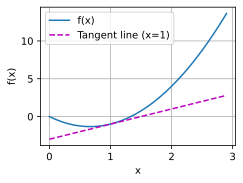

In [24]:
def use_svg_display():
    backend_inline.set_matplotlib_formats('svg')

def set_figsize(figsize=(3.5, 2.5)):
    use_svg_display()
    plt.rcParams['figure.figsize'] = figsize

def set_axes(axes, xlabel, ylabel, xlim, ylim, xscale, yscale, legend):
    axes.set_xlabel(xlabel)
    axes.set_ylabel(ylabel)
    axes.set_xscale(xscale)
    axes.set_yscale(yscale)
    axes.set_xlim(xlim)
    axes.set_ylim(ylim)
    if legend:
        axes.legend(legend)
    axes.grid()

def plot(X, Y=None, xlabel=None, ylabel=None, legend=None, xlim=None,
         ylim=None, xscale='linear', yscale='linear',
         fmts=('-', 'm--', 'g-.', 'r:'), figsize=(3.5, 2.5), axes=None):
    if legend is None:
        legend = []

    set_figsize(figsize)
    axes = axes if axes else plt.gca()

    def has_one_axis(X):
        return (hasattr(X, "ndim") and X.ndim == 1 or isinstance(X, list)
                and not hasattr(X[0], "__len__"))

    if has_one_axis(X):
        X = [X]
    if Y is None:
        X, Y = [[]] * len(X), X
    elif has_one_axis(Y):
        Y = [Y]
    if len(X) != len(Y):
        X = X * len(Y)
    axes.cla()
    for x, y, fmt in zip(X, Y, fmts):
        if len(x):
            axes.plot(x, y, fmt)
        else:
            axes.plot(y, fmt)
    set_axes(axes, xlabel, ylabel, xlim, ylim, xscale, yscale, legend)

x = np.arange(0, 3, 0.1)
plot(x, [f(x), 2 * x - 3], 'x', 'f(x)', legend=['f(x)', 'Tangent line (x=1)'])

## 2.5 自动微分

### 2.5.1 一个简单的例子

In [25]:
import torch

x = torch.arange(4.0)
print(x)
x.requires_grad_(True)  # 等价于x=torch.arange(4.0,requires_grad=True)
print(x.grad)  # 默认值是None

y = 2 * torch.dot(x, x)
print(y)
y.backward()
print(x.grad)
print(x.grad == 4 * x)

# 在默认情况下，PyTorch会累积梯度，我们需要清除之前的值
x.grad.zero_()
y = x.sum()
y.backward()
print(x.grad)

tensor([0., 1., 2., 3.])
None
tensor(28., grad_fn=<MulBackward0>)
tensor([ 0.,  4.,  8., 12.])
tensor([True, True, True, True])
tensor([1., 1., 1., 1.])


### 2.5.2 非标量变量的反向传播

In [26]:
# 对非标量调用backward需要传入一个gradient参数，该参数指定微分函数关于self的梯度。
# 本例只想求偏导数的和，所以传递一个1的梯度是合适的
x.grad.zero_()
y = x * x
# 等价于y.backward(torch.ones(len(x)))
y.sum().backward()
print(x.grad)

tensor([0., 2., 4., 6.])


### 2.5.3 分离计算

In [27]:
x.grad.zero_()
y = x * x
u = y.detach()
z = u * x

z.sum().backward()
print(x.grad == u)

x.grad.zero_()
y.sum().backward()
print(x.grad == 2 * x)

tensor([True, True, True, True])
tensor([True, True, True, True])


### 2.5.4 Python控制流的梯度计算

In [28]:
def f(a):
    b = a * 2
    while b.norm() < 1000:
        b = b * 2
    if b.sum() > 0:
        c = b
    else:
        c = 100 * b
    return c

a = torch.randn(size=(), requires_grad=True)
d = f(a)
d.backward()
print(a.grad == d / a)

tensor(True)


## 2.6 概率

### 2.6.1 基本概率论

In [29]:
%matplotlib inline
import torch
from torch.distributions import multinomial
from matplotlib import pyplot as plt

fair_probs = torch.ones([6]) / 6
print(multinomial.Multinomial(1, fair_probs).sample())
print(multinomial.Multinomial(10, fair_probs).sample())

# 将结果存储为32位浮点数以进行除法
counts = multinomial.Multinomial(1000, fair_probs).sample()
print(counts / 1000)  # 相对频率作为估计值

tensor([0., 0., 1., 0., 0., 0.])
tensor([1., 1., 3., 1., 3., 1.])
tensor([0.1630, 0.1710, 0.1690, 0.1670, 0.1520, 0.1780])


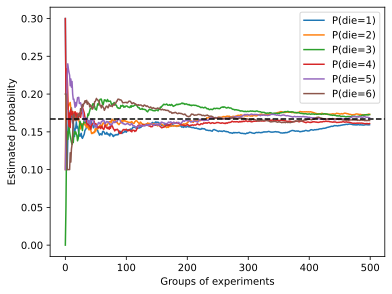

In [30]:
counts = multinomial.Multinomial(10, fair_probs).sample((500,))
cum_counts = counts.cumsum(dim=0)
estimates = cum_counts / cum_counts.sum(dim=1, keepdims=True)

set_figsize((6, 4.5))
for i in range(6):
    plt.plot(estimates[:, i].numpy(),
             label=("P(die=" + str(i + 1) + ")"))
plt.axhline(y=0.167, color='black', linestyle='dashed')
plt.gca().set_xlabel('Groups of experiments')
plt.gca().set_ylabel('Estimated probability')
plt.legend();

## 2.7 查阅文档

### 2.7.1 查找模块中的所有函数和类

In [31]:
import torch

print(dir(torch.distributions))

['AbsTransform', 'AffineTransform', 'Bernoulli', 'Beta', 'Binomial', 'CatTransform', 'Categorical', 'Cauchy', 'Chi2', 'ComposeTransform', 'ContinuousBernoulli', 'CorrCholeskyTransform', 'CumulativeDistributionTransform', 'Dirichlet', 'Distribution', 'ExpTransform', 'Exponential', 'ExponentialFamily', 'FisherSnedecor', 'Gamma', 'GeneralizedPareto', 'Geometric', 'Gumbel', 'HalfCauchy', 'HalfNormal', 'Independent', 'IndependentTransform', 'InverseGamma', 'Kumaraswamy', 'LKJCholesky', 'Laplace', 'LogNormal', 'LogisticNormal', 'LowRankMultivariateNormal', 'LowerCholeskyTransform', 'MixtureSameFamily', 'Multinomial', 'MultivariateNormal', 'NegativeBinomial', 'Normal', 'OneHotCategorical', 'OneHotCategoricalStraightThrough', 'Pareto', 'Poisson', 'PositiveDefiniteTransform', 'PowerTransform', 'RelaxedBernoulli', 'RelaxedOneHotCategorical', 'ReshapeTransform', 'SigmoidTransform', 'SoftmaxTransform', 'SoftplusTransform', 'StackTransform', 'StickBreakingTransform', 'StudentT', 'TanhTransform', 'T

### 2.7.2 查找特定函数和类的用法

In [32]:
help(torch.ones)
print(torch.ones(4))

Help on built-in function ones in module torch:

ones(...)
    ones(*size, *, out=None, dtype=None, layout=torch.strided, device=None, requires_grad=False) -> Tensor

    Returns a tensor filled with the scalar value `1`, with the shape defined
    by the variable argument :attr:`size`.

    Args:
        size (int...): a sequence of integers defining the shape of the output tensor.
            Can be a variable number of arguments or a collection like a list or tuple.

    Keyword arguments:
        out (Tensor, optional): the output tensor.
        dtype (:class:`torch.dtype`, optional): the desired data type of returned tensor.
            Default: if ``None``, uses a global default (see :func:`torch.set_default_dtype`).
        layout (:class:`torch.layout`, optional): the desired layout of returned Tensor.
            Default: ``torch.strided``.
        device (:class:`torch.device`, optional): the desired device of returned tensor.
            Default: if ``None``, uses the curre